# Gráficos de resultados — Lebú (Arauco)

Cuatro figuras para el capítulo de resultados:

1. **Curva de fragilidad** — Dunn et al. (2018), $p=\alpha\,l\,v^{n}$, con las variantes mitigadas.
2. **Perfil de generación solar y eólica** — factor de planta horario por zona.
3. **Perfil de vientos extremos** — serie horaria 2030, sostenido vs. ráfaga (EWE).
4. **Cantidad de fallas por línea** — Monte Carlo de 100 escenarios.

Todo sale de `artefactos/` y del `.nc` de clima: **el notebook no recalcula nada**, solo lee y grafica.
Si falta un artefacto, correr `python pipeline.py --estado` para ver qué etapa hace falta.

Zonas del caso Arauco (`SystemzoneV1_arauco.xlsx`):

| zona | lat | lon | |
|---|---|---|---|
| 1 | −37,645 | −73,658 | **Lebú costera** — la más severa |
| 2 | −37,715 | −73,636 | Arauco costa sur |
| 3 | −37,645 | −73,538 | **Lebú interior** |

In [37]:
from pathlib import Path
import json

import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt

APP_DIR = Path.cwd()                      # .../abc/mi_proyecto/app/app
ART = APP_DIR / "artefactos"
NC_CLIMA = APP_DIR.parent / "Proyecto oficial" / "Outputs" / "BaseHoraEWE_arauco.nc"
FIG = APP_DIR / "figuras_lebu"
FIG.mkdir(exist_ok=True)

for p in (ART / "fallas.npz", ART / "perfiles_horarios.npz", ART / "faultlin_meta.json", NC_CLIMA):
    assert p.exists(), f"falta {p} — correr la etapa correspondiente de pipeline.py"

META = json.loads((ART / "faultlin_meta.json").read_text(encoding="utf-8"))

# — Parámetros de la corrida vigente, leídos del meta (no hardcodeados) —
ALPHA   = META["dunn_alpha"]                 # 2e-17 [1/km]
EXP     = META["dunn_exp"]                   # 9.91
LARGO   = np.array(META["largo_km_por_linea"], float)
ZONA_L  = np.array(META["zonas_por_linea"], int)   # zona de cada línea
RAZON   = META["mitigadas"]["razon_clase3_clase5"]  # refuerzo: poste C5 -> C3
RHO_UG  = META["mitigadas"]["rho_ug"]              # soterramiento
H_POSTE, H_MEDICION, HELLMANN = META["altura_poste_m"], 10.0, 1/7
OFFSET  = META["anio_offset"]                # el .nc parte en 2029; el estudio usa 2030
HORAS   = META["shape"][0]
NUM_ESC = META["shape"][1]
ENLACES = set(META["lineas_enlace"])         # inmunes en la simulación

ZONAS_LEBU = [1,2,3]
NOMBRE_ZONA = {1: "Zona 1 · Lebú costera", 2: "Zona 2 · Arauco costa sur", 3: "Zona 3 · Lebú interior"}

print(f"Dunn: p = {ALPHA:.1e}·l·v^{EXP} | {HORAS} h × {NUM_ESC} escenarios × {len(LARGO)} líneas")

Dunn: p = 2.0e-17·l·v^9.91 | 8760 h × 100 escenarios × 15 líneas


In [38]:
# ── Estilo común ────────────────────────────────────────────────────────────
# Paleta categórica de orden fijo: se asigna por entidad, nunca por ranking,
# y nunca se cicla. Validada para daltonismo (ΔE ≥ 9 en el peor par adyacente).
AZUL, NARANJA, AQUA, AMARILLO = "#2a78d6", "#eb6834", "#1baf7a", "#eda100"
TINTA, TINTA_2, MUTE, GRID = "#0b0b0b", "#52514e", "#898781", "#e3e2de"

mpl.rcParams.update({
    "figure.dpi": 120, "savefig.dpi": 300, "savefig.bbox": "tight",
    "figure.facecolor": "white", "axes.facecolor": "white",
    "font.size": 9, "axes.titlesize": 11, "axes.labelsize": 9,
    "axes.titleweight": "normal", "axes.titlelocation": "center", "axes.titlepad": 10,
    "axes.edgecolor": MUTE, "axes.labelcolor": TINTA_2,
    "axes.spines.top": False, "axes.spines.right": False,
    "xtick.color": MUTE, "ytick.color": MUTE, "text.color": TINTA,
    "xtick.direction": "out", "ytick.direction": "out",
    "grid.color": GRID, "grid.linewidth": 0.6, "axes.grid.axis": "y",
    "legend.frameon": False, "legend.fontsize": 8.5,
    "lines.linewidth": 1.8, "lines.solid_capstyle": "round",
})

PRESENTACION = FIG / 'presentacion'

# ── Copias para presentación ────────────────────────────────────────────────
# Fondo transparente, textos y ejes en gris medio (se lee sobre diapositivas
# claras u oscuras) y leyendas sobre recuadro blanco. No afecta a la versión
# de la tesis, que se guarda antes.
GRIS_PRES = '#6b6b78'

def copia_presentacion(fig, nombre, carpeta):
    carpeta.mkdir(parents=True, exist_ok=True)
    fig.patch.set_alpha(0)
    for ax in fig.axes:
        ax.patch.set_alpha(0)
        for t in [ax.xaxis.label, ax.yaxis.label, ax.title, *ax.get_xticklabels(),
                  *ax.get_yticklabels(), *ax.texts]:
            t.set_color(GRIS_PRES)
        for s in ax.spines.values():
            s.set_color(GRIS_PRES)
        ax.tick_params(colors=GRIS_PRES)
    for leyenda in [ax.get_legend() for ax in fig.axes if ax.get_legend()] + list(fig.legends):
        marco = leyenda.get_frame()
        marco.set_visible(True)
        marco.set_facecolor('white')
        marco.set_edgecolor('white')
        marco.set_alpha(1)
    for ext in ('png', 'svg'):
        fig.savefig(carpeta / f'{nombre}.{ext}', facecolor='none')

def guardar(fig, nombre):
    """PNG para revisar y PDF vectorial para meterlo en LaTeX, más la copia de presentación."""
    for ext in ("png", "pdf"):
        fig.savefig(FIG / f"{nombre}.{ext}")
    copia_presentacion(fig, nombre, PRESENTACION)
    print(f"→ {FIG.name}/{nombre}.png · .pdf")

def eje(ancho=5.4, alto=3.8):
    """Una figura = un gráfico. Tamaño pensado para media página en LaTeX."""
    fig, ax = plt.subplots(figsize=(ancho, alto))
    ax.grid(True, axis="y")
    ax.set_axisbelow(True)
    return fig, ax

---
## 1. Curva de fragilidad

Curva empírica de Dunn et al. (2018) para líneas de distribución, ajustada sobre ~12.000 fallas
reales por viento en el Reino Unido (2003–2010):

$$p(v) = \min\!\left(\alpha \, l\,[\mathrm{km}] \; v^{\,n},\; 1\right), \qquad \alpha = 2\cdot10^{-17},\; n = 9{,}91$$

Escala con el largo del tramo (no hay que suponer postes por línea) e incluye la caída de árboles,
que es el mecanismo dominante en distribución.

Las medidas de *hardening* entran como curvas propias, no como un descuento posterior:

- **Refuerzo estructural** (poste clase 5 → clase 3, Darestani): la curva se evalúa en $v/\text{razón}$,
  equivalente a dividir $p$ por $\text{razón}^{\,n}$.
- **Soterramiento**: $p\cdot(1-\rho_{ug})$, con $\rho_{ug} = 0{,}95$.

→ figuras_lebu/01a_curva_fragilidad.png · .pdf


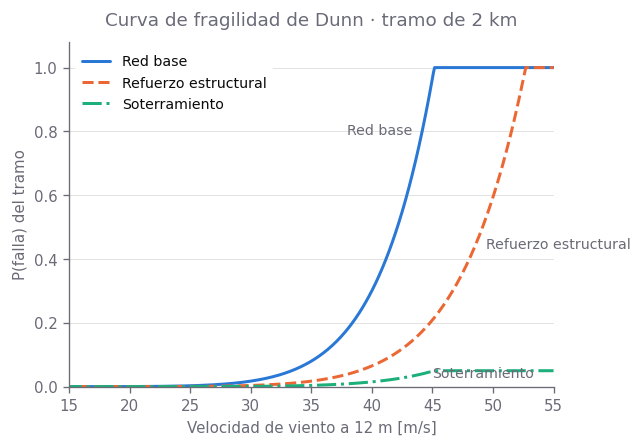

In [39]:
def p_dunn(v, largo_km, alpha=ALPHA, exp=EXP):
    """P(falla | viento) de la curva empírica, saturada en 1."""
    v = np.asarray(v, float)
    return np.minimum(alpha * largo_km * np.maximum(v, 0.0) ** exp, 1.0)

v = np.linspace(0, 55, 600)
L_REF = 2.0  # tramo de referencia [km]; ~la mediana del alimentador

# Leyenda + etiqueta directa + trazo distinto: la identidad nunca queda solo en el color.
variantes = [
    ("Red base",             p_dunn(v, L_REF),                 AZUL,    "-",  0.80, -6),
    ("Refuerzo estructural", p_dunn(v / RAZON, L_REF),         NARANJA, "--", 0.45,  6),
    ("Soterramiento",        p_dunn(v, L_REF) * (1 - RHO_UG),  AQUA,    "-.", 0.04,  6),
]

fig, ax = eje()
for etiqueta, p, color, ls, nivel, dx in variantes:
    ax.plot(v, p, color=color, ls=ls, label=etiqueta)
    j = int(np.argmin(np.abs(p - nivel)))
    ax.annotate(etiqueta, (v[j], p[j]), textcoords="offset points", xytext=(dx, 0),
                color=TINTA_2, fontsize=8.5, ha="right" if dx < 0 else "left", va="center")
ax.set(xlim=(15, 55), ylim=(0, 1.08), xlabel="Velocidad de viento a 12 m [m/s]",
       ylabel="P(falla) del tramo",
       title=f"Curva de fragilidad de Dunn · tramo de {L_REF:.0f} km")
ax.legend(loc="upper left")
fig.tight_layout()
guardar(fig, "01a_curva_fragilidad")
plt.show()

→ figuras_lebu/01b_fragilidad_vs_largo.png · .pdf


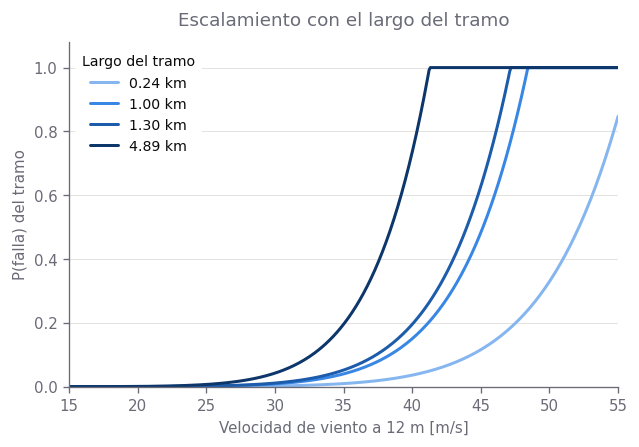

In [40]:
# Sensibilidad al largo del tramo: es lo que distingue a esta curva de las
# estructurales. Cuatro tramos representativos, no las 15 líneas encimadas.
rampa = ["#86b6ef", "#3987e5", "#1c5cab", "#0d366b"]   # secuencial, un solo tono
largos = [LARGO.min(), 1.0, float(np.median(LARGO)), LARGO.max()]

fig, ax = eje()
for l, color in zip(largos, rampa):
    ax.plot(v, p_dunn(v, l), color=color, linewidth=1.8, label=f"{l:.2f} km")
ax.legend(loc="upper left", title="Largo del tramo", title_fontsize=8.5)
ax.set(xlim=(15, 55), ylim=(0, 1.08), xlabel="Velocidad de viento a 12 m [m/s]",
       ylabel="P(falla) del tramo", title="Escalamiento con el largo del tramo")
fig.tight_layout()
guardar(fig, "01b_fragilidad_vs_largo")
plt.show()

---
## 2. Perfil de generación solar y eólica

`artefactos/perfiles_horarios.npz` trae el **factor de planta horario** (0–1) por zona: solar de
Open-Meteo en el punto de cada zona, eólico derivado del `.nc` con la curva de potencia a 30 m de buje.

Dos vistas, en dos ejes separados (nunca doble eje $y$): el día medio y el ciclo estacional.

In [41]:
ZONAS_LEBU

[1, 2, 3]

→ figuras_lebu/02a_solar_dia_medio.png · .pdf


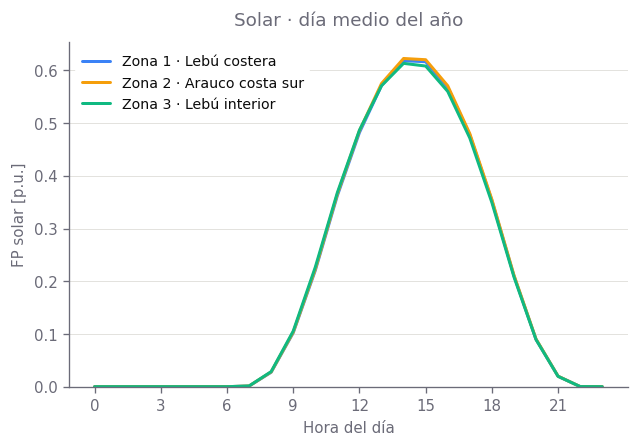

→ figuras_lebu/02b_solar_mensual.png · .pdf


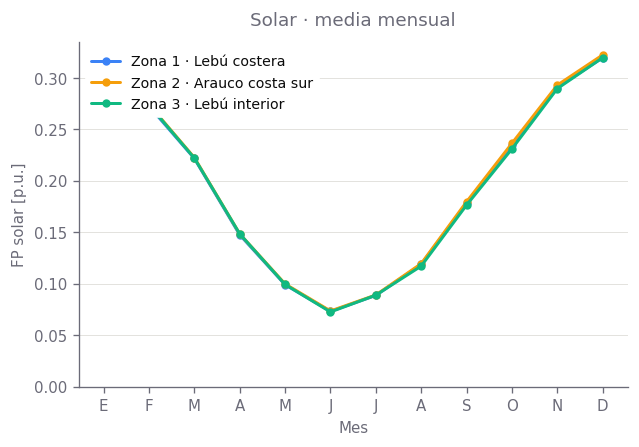

→ figuras_lebu/02c_eolico_dia_medio.png · .pdf


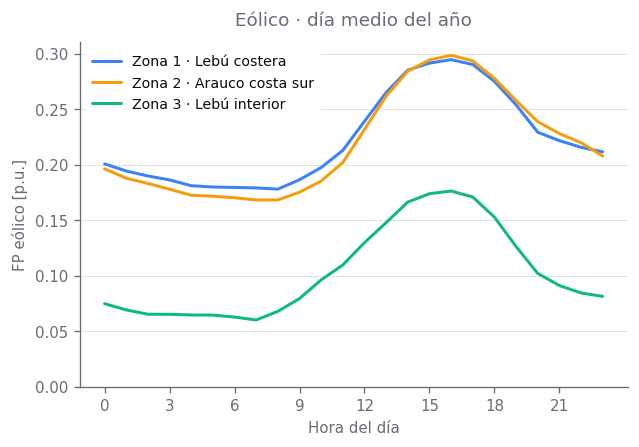

→ figuras_lebu/02d_eolico_mensual.png · .pdf


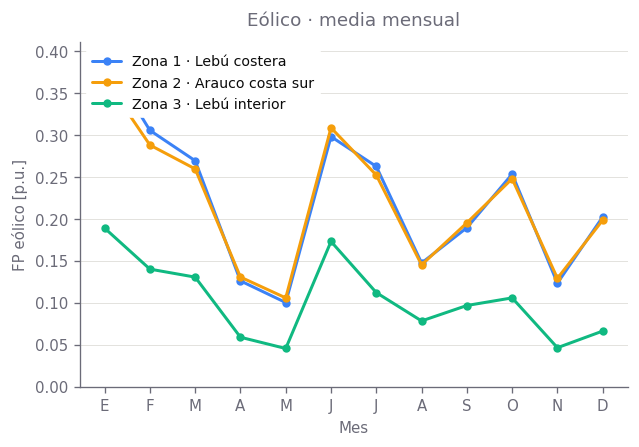

,FP solar medio,FP eólico medio
Zona 1 · Lebú costera,0.1967,0.2224
Zona 2 · Arauco costa sur,0.1980,0.2188
Zona 3 · Lebú interior,0.1961,0.1034


In [42]:
per = np.load(ART / "perfiles_horarios.npz")
zonas = list(per["zonas"])
solar, eolico = per["solar_por_zona"], per["eolico_por_zona"]     # (8760, 3)

idx = pd.date_range("2030-01-01", periods=solar.shape[0], freq="h")
col = {z: i for i, z in enumerate(zonas)}

# Color por zona: el MISMO matiz que el grafo de la red. Son los RGB de
# ZONE_FILL (grafo.py:17), que allá pintan el polígono de cada zona al 12 % de
# opacidad, y acá van opacos para que la línea se vea. La familia de color es
# la misma que en la ENS por zona (NODEFILL, graficos_valor_esperado.py:60),
# un par de pasos más saturada: el pastel de relleno de barra queda lavado
# como línea fina.
# El trazo es el segundo canal de identidad: el par zona 2 / zona 3 queda
# justo en deuteranopía (ΔE 8,9) y no puede ir a color solo.
COLOR_ZONA = {1: "#3B82F6", 2: "#F59E0B", 3: "#10B981"}   # azul · ámbar · verde
estilo_zona = {z: (COLOR_ZONA[z], ls) for z, ls in ((1, "-"), (2, "-"), (3, "-"))}

def por_hora_del_dia(serie):
    return pd.Series(serie, index=idx).groupby(idx.hour).mean()

def por_mes(serie):
    return pd.Series(serie, index=idx).groupby(idx.month).mean()

def figura_perfil(datos, nombre, agregador, titulo, archivo, xlabel, xticks, xticklabels=None):
    fig, ax = eje()
    for z in ZONAS_LEBU:
        c, ls = estilo_zona[z]
        s = agregador(datos[:, col[z]])
        ax.plot(s.index, s.values, color=c, ls=ls, label=NOMBRE_ZONA[z],
                marker="o" if xticklabels else None, ms=4)
    ax.set(ylim=(0, None), ylabel=f"FP {nombre.lower()} [p.u.]", xlabel=xlabel,
           title=titulo, xticks=xticks)
    if xticklabels:
        ax.set_xticklabels(xticklabels)
    ax.legend(loc="upper left")
    fig.tight_layout()
    guardar(fig, archivo)
    plt.show()

MESES = list("EFMAMJJASOND")
figura_perfil(solar, "Solar", por_hora_del_dia, "Solar · día medio del año",
              "02a_solar_dia_medio", "Hora del día", range(0, 24, 3))
figura_perfil(solar, "Solar", por_mes, "Solar · media mensual",
              "02b_solar_mensual", "Mes", range(1, 13), MESES)
figura_perfil(eolico, "Eólico", por_hora_del_dia, "Eólico · día medio del año",
              "02c_eolico_dia_medio", "Hora del día", range(0, 24, 3))
figura_perfil(eolico, "Eólico", por_mes, "Eólico · media mensual",
              "02d_eolico_mensual", "Mes", range(1, 13), MESES)

resumen_fp = pd.DataFrame(
    {"FP solar medio": [solar[:, col[z]].mean() for z in zonas],
     "FP eólico medio": [eolico[:, col[z]].mean() for z in zonas]},
    index=[NOMBRE_ZONA[z] for z in zonas]).round(4)
resumen_fp.to_csv(FIG / "02_factores_de_planta.csv")
resumen_fp

---
## 3. Perfil de vientos extremos

El `.nc` tiene dos escenarios en el eje `lon`: `sostenido` (tendencia climática ARClim sin ráfaga) y
`rafaga` (con la amplificación de los eventos extremos). La corrida vigente usó
**`escenario_clima = with_EWE`**, es decir la ráfaga.

El viento del `.nc` está medido a 10 m y las líneas de 20 kV están a 12 m, así que se corrige con
el perfil de potencia de Hellmann: $v_{12} = v_{10}\,(12/10)^{1/7}$.

→ figuras_lebu/03a_serie_viento_zona3.png · .pdf


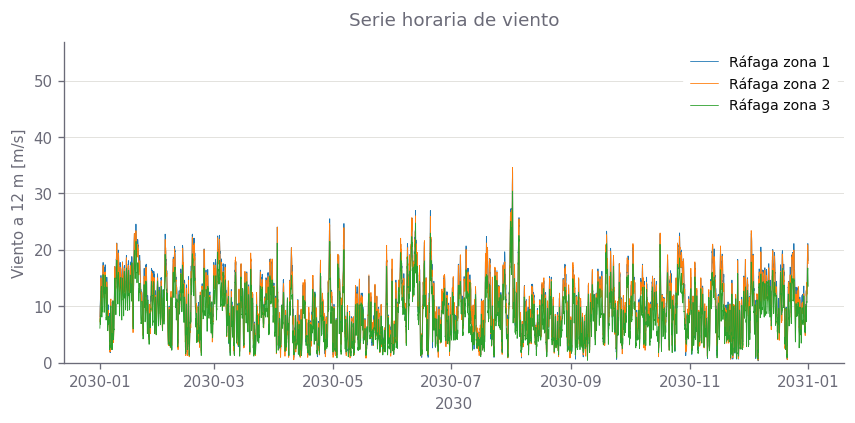

,sostenido,rafaga
Zona 1 · Lebú costera,media 5.4 · p99 12.0 · máx 18.9,media 10.6 · p99 22.7 · máx 34.4
Zona 2 · Arauco costa sur,media 5.3 · p99 12.1 · máx 19.6,media 10.3 · p99 22.2 · máx 34.6
Zona 3 · Lebú interior,media 4.1 · p99 9.9 · máx 15.8,media 8.6 · p99 19.4 · máx 30.4


In [43]:
import xarray as xr

ds = xr.open_dataset(NC_CLIMA)
lat_de_zona = {int(z): i for i, z in enumerate(ds["zone_id"].values)}
factor_altura = (H_POSTE / H_MEDICION) ** HELLMANN

# Año operativo 2030 = las 8760 h que arrancan en `OFFSET`, las mismas que leyó
# construir_faultlin.py para generar la matriz de fallas.
def viento(zona, escenario):
    i_lon = {"sostenido": 0, "rafaga": 1}[escenario]
    v = ds["wind"].values[OFFSET:OFFSET + HORAS, lat_de_zona[zona], i_lon]
    return np.asarray(v, float) * factor_altura

t = pd.date_range("2030-01-01", periods=HORAS, freq="h")

# Umbral de referencia: viento al que un tramo de 2 km alcanza P(falla)=0,5.
v_critico = (0.5 / (ALPHA * L_REF)) ** (1 / EXP)
fig, ax = eje(ancho=7.2, alto=3.6)
# ── Serie horaria del año, una figura por zona ──────────────────────────────
for z in ZONAS_LEBU:
    v_sost, v_raf = viento(z, "sostenido"), viento(z, "rafaga")
    
    # ax.plot(t, v_sost,  lw=0.5, label="Sostenido (tendencia climática)")
    ax.plot(t, v_raf,  lw=0.5, label=f"Ráfaga zona {z}")
    # ax.axhline(v_critico, color=TINTA_2, lw=1.0, ls=":")
    # ax.annotate(f"P(falla) = 0,5 para un tramo de 2 km  →  {v_critico:.1f} m/s",
    #             (t[-1], v_critico), textcoords="offset points", xytext=(0, 4),
    #             ha="right", color=TINTA_2, fontsize=8)
    # i_max = int(np.argmax(v_raf))   # el pico del año es la hora que manda en el Monte Carlo
    # ax.annotate(f"máx {v_raf[i_max]:.1f} m/s\n{t[i_max]:%d-%m}", (t[i_max], v_raf[i_max]),
    #             textcoords="offset points", xytext=(6, 2), color=TINTA_2, fontsize=8)
    ax.set(ylim=(0, v_critico * 1.35), ylabel="Viento a 12 m [m/s]", xlabel="2030",
           title="Serie horaria de viento")
    # ax.legend(loc="upper left", ncol=2)
    fig.tight_layout()

ax.legend()
guardar(fig, f"03a_serie_viento_zona{z}")
plt.show()

# # ── Cola superior: horas del año sobre cada umbral ──────────────────────────
# # Escala log; la curva se corta donde la cuenta llega a cero (log no admite 0).
# umbrales = np.arange(15, np.ceil(v_critico) + 1, 1.0)
# fig, ax = eje()
# for z in ZONAS_LEBU:
#     c, ls = estilo_zona[z]
#     vv = viento(z, "rafaga")
#     horas_sobre = np.array([(vv >= u).sum() for u in umbrales], float)
#     vis = horas_sobre > 0
#     ax.plot(umbrales[vis], horas_sobre[vis], color=c, ls=ls, label=NOMBRE_ZONA[z])
# ax.axvline(v_critico, color=TINTA_2, lw=1.0, ls=":")
# ax.annotate("P(falla) = 0,5", (v_critico, 1), rotation=90, va="bottom", ha="right",
#             textcoords="offset points", xytext=(-3, 0), color=TINTA_2, fontsize=8)
# ax.set_yscale("log")
# ax.set(xlabel="Umbral de viento [m/s]", ylabel="Horas del año sobre el umbral",
#        title="Cola superior de la distribución de viento")
# ax.legend(loc="upper right")
# fig.tight_layout()
# guardar(fig, "03b_cola_viento")
# plt.show()

resumen_v = pd.DataFrame(
    {esc: {NOMBRE_ZONA[zz]: viento(zz, esc) for zz in zonas} for esc in ("sostenido", "rafaga")}
).apply(lambda col_: col_.map(
    lambda a: f"media {a.mean():.1f} · p99 {np.percentile(a, 99):.1f} · máx {a.max():.1f}"))
resumen_v.to_csv(FIG / "03_resumen_viento.csv")
resumen_v

---
## 4. Cantidad de fallas por línea

`artefactos/fallas.npz` guarda la matriz `(8760 h × 100 escenarios × 15 líneas)` de la simulación
Monte Carlo, con una variante por medida de *hardening* (red base, refuerzo estructural y soterramiento; la gestión de vegetación se omite). Se cuenta el **inicio** de cada evento
(una falla ocupa `horas_reparacion` horas seguidas, así que contar horas fuera de servicio
sobreestimaría el número de eventos), y se divide por el número de escenarios de la muestra severa (los 10 de `muestra.json`, no los 100 simulados) para dejarlo en
**fallas esperadas por línea y por año**.

Las líneas de enlace (12, 13, 14) se declararon inmunes en la simulación y quedan en cero a propósito.

In [44]:
fz = np.load(ART / "fallas.npz")
# Gestión de vegetación queda fuera a propósito: su curva (factor de Canham en
# construir_faultlin.factor_vegetacion) no está validada para la tesis.
VARIANTES = {"Red base": "faultlinMC",
             "Refuerzo estructural": "faultlinMC_ref", "Soterramiento": "faultlinMC_ug"}
COLOR_VAR = {"Red base": AZUL, "Refuerzo estructural": NARANJA, "Soterramiento": AQUA}

# Los 10 escenarios severos sobre los que se evalúa todo el capítulo (índices internos,
# los del eje de escenarios de la matriz), no los 100 de la simulación completa.
ESC_SEV = json.loads((APP_DIR / "figuras_presentacion_severo" / "muestra.json").read_text(encoding="utf-8"))["escenarios_internos"]
assert len(ESC_SEV) == 10

def eventos_por_linea(clave, esc=ESC_SEV):
    """Fallas esperadas por línea y por año: inicios de evento / nº de escenarios de `esc`."""
    m = fz[clave][:, esc, :].astype(bool)                    # (horas, esc, líneas)
    inicios = m.copy()
    inicios[1:] &= ~m[:-1]                          # 0→1 es un evento nuevo
    return inicios.sum(axis=(0, 1)) / m.shape[1]

fallas = pd.DataFrame({nom: eventos_por_linea(k) for nom, k in VARIANTES.items()})
fallas.index = [f"L{i}" for i in range(len(LARGO))]
fallas.insert(0, "zona", ZONA_L)
fallas.insert(1, "largo_km", LARGO)
fallas.to_csv(FIG / "04_fallas_por_linea.csv")
fallas.round(2)

,zona,largo_km,Red base,Refuerzo estructural,Soterramiento
L0,1,2.82,1.05,0.24,0.05
L1,1,4.42,1.89,0.39,0.08
L2,1,0.61,0.26,0.06,0.00
L3,1,0.56,0.18,0.06,0.01
L4,3,1.54,0.22,0.02,0.00
L5,2,1.67,0.52,0.11,0.03
L6,2,0.32,0.07,0.04,0.03
L7,3,0.77,0.08,0.01,0.00
L8,3,0.33,0.03,0.01,0.01
L9,1,1.30,0.47,0.08,0.03


→ figuras_lebu/04a_fallas_por_linea.png · .pdf


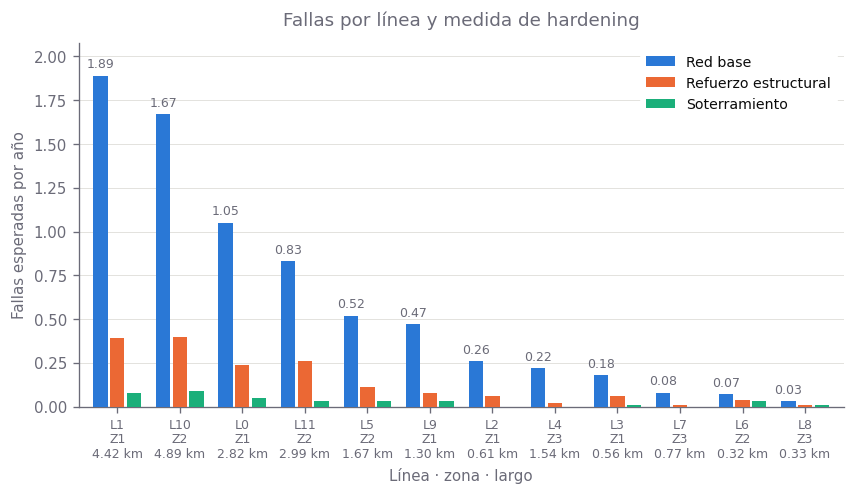

→ figuras_lebu/04b_fallas_totales.png · .pdf


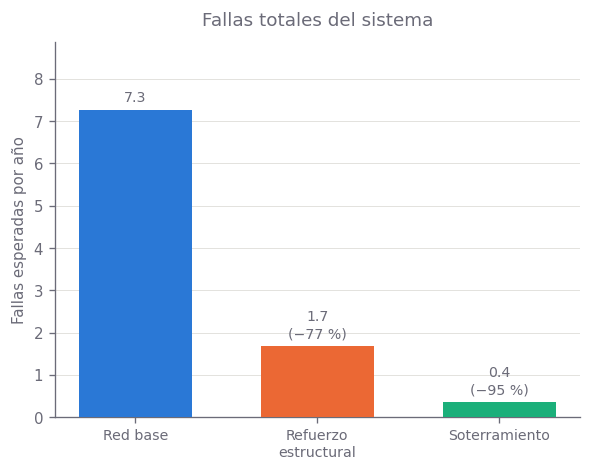

In [45]:
import textwrap

activas = fallas[fallas["Red base"] > 0].sort_values("Red base", ascending=False)
nombres = list(VARIANTES)

# ── Fallas por línea y medida ───────────────────────────────────────────────
fig, ax = eje(ancho=7.2, alto=4.2)
x = np.arange(len(activas))
ancho = 0.8 / len(nombres)
for k, nom in enumerate(nombres):            # el color sigue a la medida, nunca al ranking
    off = (k - (len(nombres) - 1) / 2) * ancho
    ax.bar(x + off, activas[nom], width=ancho * 0.86,   # el 0.86 deja el respiro entre barras
           color=COLOR_VAR[nom], label=nom, zorder=3)
off_base = -(len(nombres) - 1) / 2 * ancho
for i, (etq, fila) in enumerate(activas.iterrows()):     # etiqueta directa solo del caso base
    ax.annotate(f"{fila['Red base']:.2f}".replace(".", ","), (x[i] + off_base, fila["Red base"]),
                textcoords="offset points", xytext=(0, 3), ha="center", va="bottom",
                fontsize=7.5, color=TINTA_2)
ax.set_xticks(x)
# Tres renglones cortos en vez de uno largo: con 12 líneas no caben horizontales.
ax.set_xticklabels([f"{i}\nZ{activas.loc[i, 'zona']}\n{activas.loc[i, 'largo_km']:.2f} km"
                    for i in activas.index], fontsize=7.5, linespacing=1.15)
ax.margins(x=0.02, y=0.10)
ax.set(xlabel="Línea · zona · largo", ylabel="Fallas esperadas por año",
       title="Fallas por línea y medida de hardening")
ax.legend(loc="upper right")
fig.tight_layout()
guardar(fig, "04a_fallas_por_linea")
plt.show()

# ── Total del sistema ───────────────────────────────────────────────────────
tot = fallas[nombres].sum()
fig, ax = eje(ancho=5.0, alto=4.0)
ax.bar(range(len(tot)), tot.values, color=[COLOR_VAR[n] for n in tot.index],
       width=0.62, zorder=3)
base = tot["Red base"]
for i, (nom, v_) in enumerate(tot.items()):
    txt = (f"{v_:.1f}" if nom == "Red base" else f"{v_:.1f}\n(−{100 * (1 - v_ / base):.0f} %)").replace(".", ",")
    ax.annotate(txt, (i, v_), textcoords="offset points", xytext=(0, 5),
                ha="center", fontsize=8.5, color=TINTA_2, linespacing=1.3)
ax.set_xticks(range(len(tot)))
ax.set_xticklabels(["\n".join(textwrap.wrap(n, 12, break_long_words=False)) for n in tot.index],
                   fontsize=8.5, color=TINTA_2)
ax.set(ylabel="Fallas esperadas por año", title="Fallas totales del sistema")
ax.margins(y=0.22)
fig.tight_layout()
guardar(fig, "04b_fallas_totales")
plt.show()

---
### Salidas

En `figuras_lebu/`, **una figura por gráfico**, cada una en `.png` (revisión) y `.pdf`
(vectorial, para `\includegraphics`), más los `.csv` con los números que hay detrás:

| archivo | contenido |
|---|---|
| `01a_curva_fragilidad` | curva de Dunn: red base y las dos medidas de hardening |
| `01b_fragilidad_vs_largo` | la misma curva para cuatro largos de tramo |
| `02a_solar_dia_medio` · `02c_eolico_dia_medio` | factor de planta por hora del día |
| `02b_solar_mensual` · `02d_eolico_mensual` | factor de planta medio por mes |
| `02_factores_de_planta.csv` | FP medio anual por zona |
| `03a_serie_viento_zona<z>` | serie horaria 2030, sostenido vs. ráfaga, una por zona |
| `03b_cola_viento` | horas del año sobre cada umbral de viento |
| `03_resumen_viento.csv` | media, p99 y máximo por zona y escenario |
| `04a_fallas_por_linea` | fallas esperadas por línea y medida |
| `04b_fallas_totales` | total del sistema y abatimiento de cada medida |
| `04_fallas_por_linea.csv` | la tabla completa, incluidas las líneas de enlace |